In [1]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import pandas as pd
from scipy.linalg import expm, eigvals
from matplotlib.lines import Line2D
from itertools import product
import math

In [2]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,
})


# Fig 1 (a)

In [5]:
def growth(Q, tau, nu, dt, PopSize=10**4, steps=None): #Pop dynamics simulation
    if steps is None:
        steps = int(Q * tau / dt * 40)
    
    H = np.array([1] + [0]*(Q-1))
    indices = np.concatenate((np.arange(1, Q), [0]))
    Pop = np.random.multinomial(PopSize, [1/Q]*Q)
    AvH = [np.sum(Pop * H)/PopSize]
    
    Kswitch = int(tau/dt)
    
    for k in range(1, steps+1):
        # environmental switch
        if k > Kswitch:
            H = H[indices]
            Kswitch += int(tau/dt)
        
        # selection
        Proba = np.exp(H*dt) * Pop
        Proba /= np.sum(Proba)+1e-16
        Proba=np.maximum(0,Proba)
        Proba=np.minimum(1,Proba)
        Pop = np.random.multinomial(PopSize, Proba)
        # vectorized mutation / ν switching
        switch_out = np.random.binomial(Pop, nu*dt)
        stay = Pop - switch_out
        # redistribute switched individuals uniformly
        redistributed = np.random.multinomial(np.sum(switch_out), [1/Q]*Q)
        Pop = stay + redistributed
        
        AvH.append(np.sum(Pop * H)/PopSize)
    
    return np.mean(AvH[2*int(tau/dt):])

# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list(Q, tau, nu_list, dt, PopSize=10**4, steps=None, n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(growth)(Q, tau, nu, dt, PopSize, steps) for nu in nu_list
    )
    return results




# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()
    A0 += np.diag([k0 -L- nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 -L- nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 -L- nu for (k0,k1,k2) in Ks])
    A3 += np.diag([-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return (np.log(lam_max)+4*L*tau) / (4 * tau)



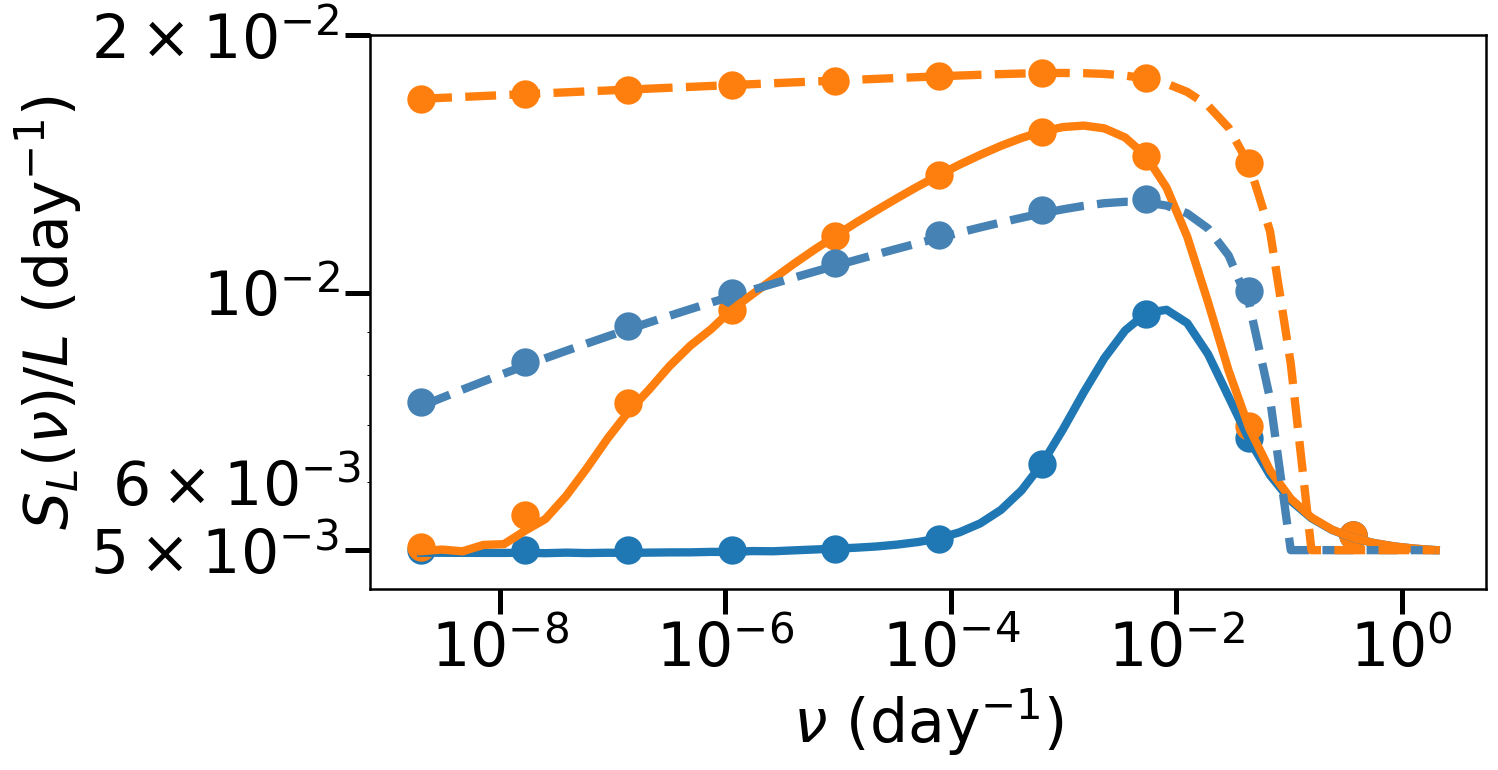

In [35]:
plt.figure(figsize=(12, 6))

# === Parameters ===
Q = 4
s=2e-2 # for the rescaling of times
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [5,  20]

dt=1e-2
PopSize=10**8
nu_list_complete = np.logspace(-7, 2, 50)  # equivalent to ν in your Mathematica code
nu_list = nu_list_complete[::5]

for tau in taus:
    S1_simu=np.array(growth_for_nu_list(Q, tau, nu_list_complete, dt, PopSize=10**8, steps=None, n_jobs=-1))
    S1_exact= np.array([ r_inf_exact_Q4(1,tau, nu) for nu in nu_list])
    plt.scatter(nu_list*s,s*S1_exact)
    plt.plot(nu_list_complete*s, s*S1_simu)

ind=0
Colour=['steelblue',"tab:orange"]
for tau in taus:
    L=10
    S1_approx = np.maximum(L/Q,L-nu_list_complete*(1-Q**(-L))+np.log(2*nu_list_complete/Q**L/L)/tau)/L
    S1_exact= np.array([ r_inf_exact_Q4(L,tau, nu)/L for nu in nu_list])
    plt.scatter(nu_list*s,S1_exact*s,c=Colour[ind])
    plt.plot(nu_list_complete*s, S1_approx*s,'--',c=Colour[ind])
    ind+=1

plt.semilogx()
plt.semilogy()
plt.ylim((0.0045,0.02))
plt.yticks([0.005,0.01,0.02],[r'$5\times 10^{-3}$',r'$10^{-2}$',r'$2 \times 10^{-2}$'])

plt.xlabel(r'$\nu~(\text{day}^{-1})$')
plt.ylabel(r'$S_L(\nu)/L~(\text{day}^{-1})$')

plt.savefig('Fig1_a.svg')

# Fig 1 b)

In [3]:
def compute_r_value(L, Q, tau, nu):

    approx = max(
        L / Q,
        L - nu * (1 - Q**(-L)) + np.log(nu / Q**L / L) / tau
    )
    return approx

22


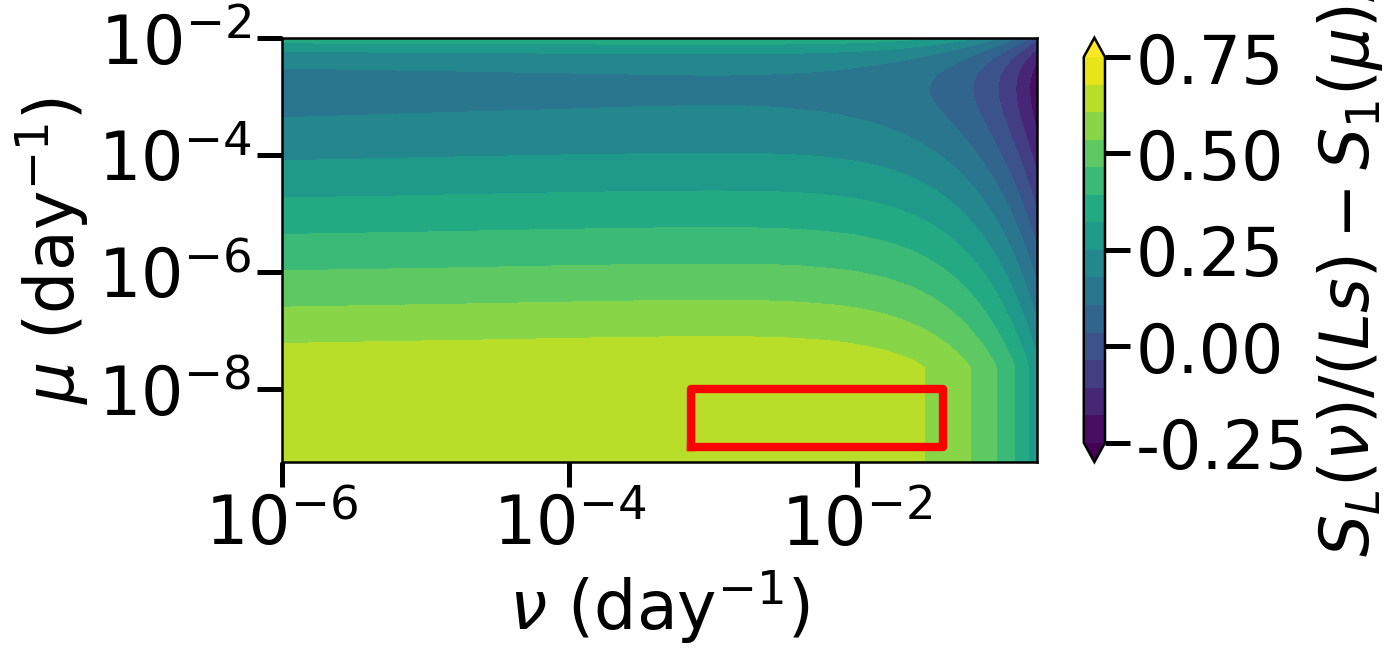

In [18]:
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import FormatStrFormatter, LogLocator, LogFormatterSciNotation

# ===============================
# Parameters
# ===============================

s=2e-2
Q=4

tau_fixed=10**3*s 

mu_vals = np.logspace(-9.25,-2, 60)/s
nu_vals  = np.logspace(-6,-0.75, 60)/s

# ===============================
# Compute values
# ===============================
L = 22

val_mu = Parallel(n_jobs=-1)(
        delayed(compute_r_value)(1, Q, tau_fixed, mu)
        for mu in mu_vals)

val_mu=22*np.array(val_mu)
print(L)
val_nu = Parallel(n_jobs=-1)(
        delayed(compute_r_value)(L, Q, tau_fixed, nu)
        for nu in nu_vals)

difference = np.zeros((len(nu_vals), len(mu_vals)))
for j in range(len(mu_vals)):
    for i in range(len(nu_vals)):
        difference[i,j]=(val_nu[j]-val_mu[i])/L*s

plt.figure(figsize=(12, 6))

# Set levels to match the desired colorbar range
levels = np.linspace(-0.25, 0.75, 15)
cont = plt.contourf(
    nu_vals * s, mu_vals * s, difference / s,
    levels=levels,
    cmap="viridis",
    extend="both"
)

# Add contours for gamma
gamma_vals = np.array([1, 2,4]) * s
colors = ['red', 'black', 'magenta']
linestyles = ['-', '--', ':']
legend_elements = []

#for gamma, color, linestyle in zip(gamma_vals, colors, linestyles):
#    plt.contour(
#        nu_vals * s, mu_vals * s, difference / s - gamma / s / L,
#        levels=[0],
#        colors=color,
#        linestyles=linestyle,
#        linewidths=4,
#    )
#    legend_elements.append(
#        Line2D([0], [0], color=color, linestyle=linestyle, linewidth=8, label=f'γ = {gamma:.2e}')
#    )

# Colorbar
S = 40
cbar = plt.colorbar(cont)
cbar.set_ticks(np.linspace(-0.25, 0.75, 5))  # Matches the levels
cbar.set_label(r'$S_L(\nu)/(Ls) - S_1(\mu)/s$', fontsize=S)
cbar.ax.tick_params(labelsize=S)
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))



# Log scale and ticks
plt.xscale('log')
plt.yscale('log')
ax = plt.gca()
ax.xaxis.set_major_locator(LogLocator(numticks=5))
ax.xaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase=False))
ax.yaxis.set_major_locator(LogLocator(numticks=5))
ax.yaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase=False))
plt.plot([7e-4, 7e-4,4e-2,4e-2,7e-4],[1e-9, 1e-8, 1e-8,1e-9,1e-9],'red')
plt.xticks([1e-6,1e-4,1e-2],fontsize=S)
plt.yticks(fontsize=S)
plt.xlabel(r'$\nu~(\text{day}^{-1})$', fontsize=S)
plt.ylabel(r'$\mu~(\text{day}^{-1})$', fontsize=S)

# Legend
#plt.legend(handles=legend_elements, loc='upper right', fontsize=S-10)



plt.tight_layout()
plt.savefig('Fig_1b.svg', dpi=300, bbox_inches='tight')
plt.show()